# Lesson 1 — StatsBomb event analysis and shot maps
## Goal
Explore the 2019 Women's World Cup, analyse England–Sweden (match 69301), and explain England's shooting using events and expected goals (xG).

Based on Soccermatics [Using StatsBomb](https://soccermatics.readthedocs.io/en/latest/gallery/plot_UsingStatsbomb.html) and [Plotting Shots](https://soccermatics.readthedocs.io/en/latest/gallery/lesson1/plot_PlottingShots.html). We extend its half-pitch example with xG marker areas and calculated insights.

Data: [StatsBomb Open Data](https://github.com/statsbomb/open-data). Credit: StatsBomb. This notebook downloads live open data; reruns may reflect source updates. No tracking dataset is loaded.

## 1. Setup and imports
Use the existing project virtual environment. Run all cells in order. `Sbopen` loads and flattens StatsBomb JSON into pandas tables; `VerticalPitch` handles the coordinate rotation for plotting.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Sbopen, VerticalPitch
from IPython.display import display, Markdown

parser = Sbopen()
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / 'notebooks').is_dir(), 'Start Jupyter from the project root or notebooks folder.'
FIGURE_PATH = PROJECT_ROOT / 'figures' / '01_shot_map.png'
FIGURE_PATH.parent.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})
print('Python:', sys.version.split()[0])

Python: 3.11.4


## 2. Explore competitions
A **competition** is a league or tournament, such as the Women's World Cup. A **season** identifies one edition, such as 2019. IDs are stable keys for joining and requesting data; names alone may be ambiguous. Request matches with both competition and season IDs.

In [2]:
competitions = parser.competition()
display(competitions.head())
display(competitions.loc[(competitions.competition_id == 72) & (competitions.season_id == 30),
                         ['competition_id', 'season_id', 'competition_name', 'season_name']])

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
0,9,281,Germany,1. Bundesliga,male,False,False,2023/2024,2024-09-28T20:46:38.893391,2025-11-15T23:17:41.827093,2025-11-15T23:17:41.827093,2024-09-28T20:46:38.893391
1,9,27,Germany,1. Bundesliga,male,False,False,2015/2016,2024-05-19T11:11:14.192381,NaN,NaN,2024-05-19T11:11:14.192381
2,1267,107,Africa,African Cup of Nations,male,False,True,2023,2026-05-12T21:18:08.827431,2026-05-02T02:07:18.902396,2026-05-02T02:07:18.902396,2026-05-12T21:18:08.827431
3,16,4,Europe,Champions League,male,False,False,2018/2019,2026-05-15T15:54:04.598614,2021-06-13T16:17:31.694,NaN,2026-05-15T15:54:04.598614
4,16,1,Europe,Champions League,male,False,False,2017/2018,2024-02-13T02:35:28.134882,2021-06-13T16:17:31.694,NaN,2024-02-13T02:35:28.134882


,competition_id,season_id,competition_name,season_name
79,72,30,Women's World Cup,2019


## 3. Explore matches
Match data has one row per fixture: date, teams, score and competition metadata. We use competition 72 and season 30 from the tutorial.

In [3]:
matches = parser.match(competition_id=72, season_id=30)
display(matches.head())
display(matches[['match_id', 'match_date', 'home_team_name', 'away_team_name', 'home_score', 'away_score']].head(10))
match = matches.loc[matches.match_id == 69301].iloc[0]
display(match[['match_id', 'match_date', 'home_team_name', 'away_team_name', 'home_score', 'away_score']].to_frame('Value'))

,match_id,match_date,kick_off,home_score,away_score,match_status,...,stadium_country_id,stadium_country_name,referee_id,referee_name,referee_country_id,referee_country_name
0,69284,2019-07-03,2019-07-03 19:00:00,1,0,available,...,78,France,1627.0,Marie-Soleil Beaudoin,40.0,Canada
1,68312,2019-06-18,2019-06-18 19:00:00,0,1,available,...,78,France,1638.0,Lucila Venegas Montes,147.0,Mexico
2,69163,2019-06-24,2019-06-24 19:00:00,1,0,available,...,78,France,1640.0,Katherine Margaret Jacewicz,14.0,Australia
3,22964,2019-06-15,2019-06-15 13:00:00,3,1,available,...,78,France,NaN,NaN,NaN,NaN
4,69301,2019-07-06,2019-07-06 15:00:00,1,2,available,...,78,France,2077.0,Anastasia Pustovoytova,188.0,Russia


,match_id,match_date,home_team_name,away_team_name,home_score,away_score
0,69284,2019-07-03,Netherlands Women's,Sweden Women's,1,0
1,68312,2019-06-18,Italy Women's,Brazil Women's,0,1
2,69163,2019-06-24,Sweden Women's,Canada Women's,1,0
3,22964,2019-06-15,Netherlands Women's,Cameroon W,3,1
4,69301,2019-07-06,England Women's,Sweden Women's,1,2
5,22963,2019-06-14,Jamaica Women's,Italy Women's,0,5
6,69137,2019-06-23,France Women's,Brazil Women's,2,1
7,68355,2019-06-22,Germany Women's,Nigeria Women's,3,0
8,68357,2019-06-22,Norway Women's,Australia Women's,1,1
9,22973,2019-06-16,Sweden Women's,Thailand W,5,1


,Value
match_id,69301
match_date,2019-07-06 00:00:00
home_team_name,England Women's
away_team_name,Sweden Women's
home_score,1
away_score,2


## 4. Load match events
**Event data** records discrete actions (passes, shots, pressures), with time, player and location. It does not show every player's movement between actions. **Tracking data** records player and ball positions at frequent time intervals. **Freeze-frame data** provides a spatial snapshot at selected moments, here shots; it is not continuous tracking and may not include all players.

`related` links associated events, `freeze` contains shot snapshots, and `tactics` contains player positions/lineup information associated with tactical events. Missing columns on some events are often structural: passes do not have shot xG.

In [4]:
events, related, freeze, tactics = parser.event(69301)
display(events.head())
events.info()
display(events['type_name'].value_counts())
print(f'{len(events):,} events; {len(related):,} related rows; {len(freeze):,} freeze-frame rows; {len(tactics):,} tactics rows')

,id,index,period,timestamp,minute,second,...,pass_no_touch,block_save_block,foul_committed_advantage,foul_won_advantage,foul_committed_card_id,foul_committed_card_name
0,a64eeb01-dede-4a3e-b959-c6162a73b027,1,1,00:00:00,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN
1,e5410151-8490-4aab-a19b-ac1ed2e5e168,2,1,00:00:00,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN
2,34971410-7630-45eb-98f3-374db37cd893,3,1,00:00:00,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN
3,82ee85d3-4e1a-4327-8139-6a055b04874e,4,1,00:00:00,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN
4,75dd933f-99b9-4f85-9cab-8e3865c3e8c0,5,1,00:00:00.140000,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 3289 entries, 0 to 3288
Data columns (total 73 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              3289 non-null   str    
 1   index                           3289 non-null   int64  
 2   period                          3289 non-null   int64  
 3   timestamp                       3289 non-null   object 
 4   minute                          3289 non-null   int64  
 5   second                          3289 non-null   int64  
 6   possession                      3289 non-null   int64  
 7   duration                        2457 non-null   float64
 8   match_id                        3289 non-null   int64  
 9   type_id                         3289 non-null   int64  
 10  type_name                       3289 non-null   str    
 11  possession_team_id              3289 non-null   int64  
 12  possession_team_name            3289 non-null

type_name
Pass               921
Ball Receipt       832
Carry              765
Pressure           236
Ball Recovery      126
Duel                72
Clearance           57
Block               41
Dispossessed        35
Goal Keeper         29
Dribble             25
Miscontrol          25
Foul Committed      23
Interception        19
Foul Won            19
Shot                19
Dribbled Past       18
Injury Stoppage      6
Substitution         6
Half Start           4
Half End             4
Starting XI          2
Error                2
Tactical Shift       2
Bad Behaviour        1
Name: count, dtype: int64

3,289 events; 6,268 related rows; 232 freeze-frame rows; 44 tactics rows


## 5. Analyse shots and xG
A boolean filter selects shots; `.copy()` makes an independent table for derived columns. A **shot** is an attempt, whether scored, saved, blocked or missed. A **goal** here is a shot with outcome `Goal`; own goals are separate events.

**Expected goals (xG)** estimates the probability that a chance becomes a goal, based on the provider's model and shot context. A 0.20 xG shot represents about a 20% scoring probability for comparable chances. Summing xG measures chance quality and quantity together, not a guaranteed score. We use StatsBomb's supplied values, rather than training a model.

In [5]:
shots = events[events['type_name'] == 'Shot'].copy()
shots['is_goal'] = shots['outcome_name'].eq('Goal')
display(shots[['player_name', 'team_name', 'x', 'y', 'outcome_name', 'shot_statsbomb_xg']])
assert not shots[['x', 'y', 'shot_statsbomb_xg']].isna().any().any()
assert shots.shot_statsbomb_xg.between(0, 1).all()
assert shots.x.between(0, 120).all() and shots.y.between(0, 80).all()
print('Total shots:', len(shots))
team_summary = shots.groupby('team_name').agg(shots=('id', 'size'), goals=('is_goal', 'sum'), xg=('shot_statsbomb_xg', 'sum'))
display(team_summary.round(3))

,player_name,team_name,x,y,outcome_name,shot_statsbomb_xg
339,Kosovare Asllani,Sweden Women's,104.7,45.5,Goal,0.105188
530,Eva Sofia Jakobsson,Sweden Women's,110.9,53.1,Saved to Post,0.039004
719,Eva Sofia Jakobsson,Sweden Women's,107.8,26.1,Goal,0.035328
741,Lucy Bronze,England Women's,93.7,51.1,Saved,0.018011
955,Francesca Kirby,England Women's,108.0,52.7,Goal,0.100729
1326,Hanna Erica Maria Glas,Sweden Women's,83.6,47.1,Saved,0.006903
1484,Emma Stina Blackstenius,Sweden Women's,105.4,25.5,Off T,0.124660
1576,Ellen White,England Women's,108.4,53.3,Saved,0.139090
1781,Alex Greenwood,England Women's,84.3,31.3,Blocked,0.006838
1793,Jade Moore,England Women's,81.9,35.2,Off T,0.006616


Total shots: 19


,shots,goals,xg
team_name,,,
England Women's,11,1,0.474
Sweden Women's,8,2,0.549


### Player rankings
Grouping sums a player’s chances across this match. These are single-match totals, not season scouting measures.

In [6]:
player_summary = shots.groupby(['team_name', 'player_name']).agg(shots=('id', 'size'), goals=('is_goal', 'sum'), xg=('shot_statsbomb_xg', 'sum'))
display(player_summary.sort_values(['shots', 'xg'], ascending=False).head(10).round(3))
display(player_summary.sort_values('xg', ascending=False).head(10).round(3))

shots  goals     xg
team_name       player_name                                 
Sweden Women's  Eva Sofia Jakobsson          3      1  0.145
England Women's Lucy Bronze                  3      0  0.117
Sweden Women's  Julia Zigiotti-Olme          2      0  0.168
England Women's Jade Moore                   2      0  0.013
                Ellen White                  1      0  0.139
Sweden Women's  Emma Stina Blackstenius      1      0  0.125
                Kosovare Asllani             1      1  0.105
England Women's Francesca Kirby              1      1  0.101
                Stephanie Houghton           1      0  0.057
                Jill Scott                   1      0  0.021

shots  goals     xg
team_name       player_name                                 
Sweden Women's  Julia Zigiotti-Olme          2      0  0.168
                Eva Sofia Jakobsson          3      1  0.145
England Women's Ellen White                  1      0  0.139
Sweden Women's  Emma Stina Blackstenius      1      0  0.125
England Women's Lucy Bronze                  3      0  0.117
Sweden Women's  Kosovare Asllani             1      1  0.105
England Women's Francesca Kirby              1      1  0.101
                Stephanie Houghton           1      0  0.057
                Jill Scott                   1      0  0.021
                Karen Julia Carney           1      0  0.019

## 6. England shot map
StatsBomb uses a 120 × 80 coordinate grid, with the attack normalised towards x=120. These are provider coordinates, not measured metres. The half-pitch shows x≥60; `VerticalPitch.scatter` rotates the display so the goal is at the top. Marker **area** is proportional to xG; filled diamonds are goals, open circles are other shots. Overlapping shots can obscure each other.

We explicitly check that no selected shot is hidden on the defensive half.

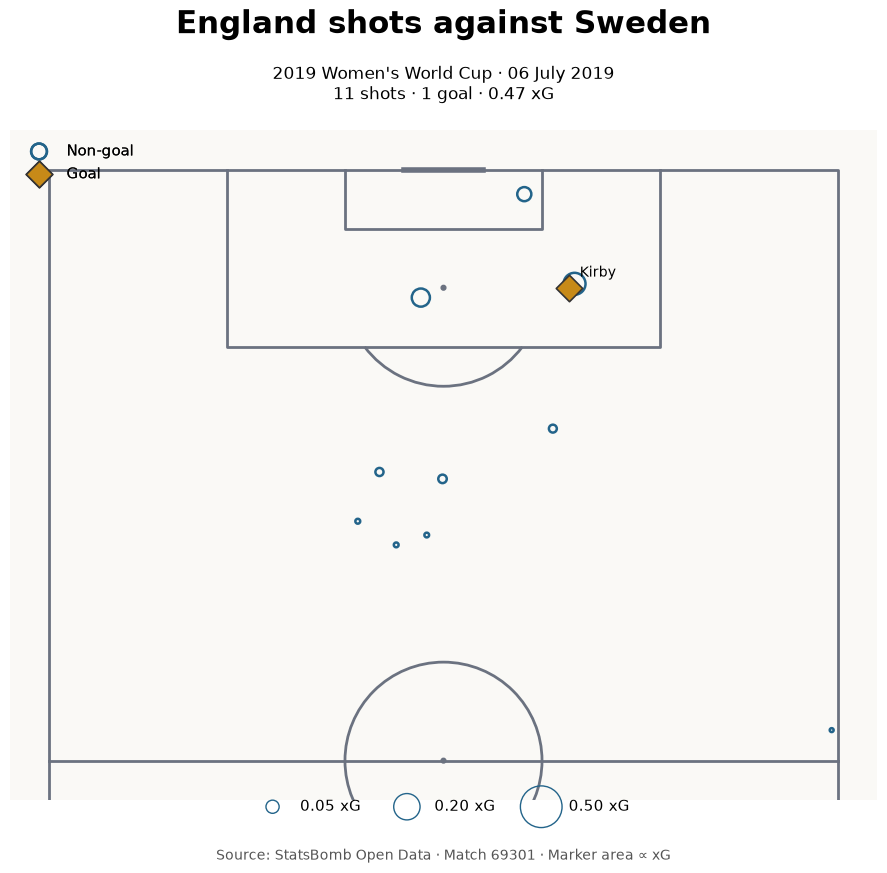

Saved: /Users/alireza/football-analytics/figures/01_shot_map.png


In [7]:
TEAM = match.home_team_name
team_shots = shots.loc[shots.team_name.eq(TEAM)].copy()
assert TEAM == "England Women\'s"
assert team_shots.x.ge(60).all(), 'A half-pitch would omit a shot; use a full pitch.'
goals = team_shots.loc[team_shots.is_goal]
non_goals = team_shots.loc[~team_shots.is_goal]
AREA_SCALE = 1800
pitch = VerticalPitch(pitch_type='statsbomb', half=True, pitch_color='#faf9f6', line_color='#6b7280', line_zorder=1)
fig, ax = pitch.draw(figsize=(9, 9))
fig.subplots_adjust(top=0.81, bottom=0.23)
pitch.scatter(non_goals.x, non_goals.y, s=non_goals.shot_statsbomb_xg * AREA_SCALE,
              marker='o', facecolors='none', edgecolors='#23648a', linewidths=1.8, label='Non-goal', ax=ax, zorder=3)
pitch.scatter(goals.x, goals.y, s=goals.shot_statsbomb_xg * AREA_SCALE,
              marker='D', color='#c78a18', edgecolors='#343434', linewidths=1.2, label='Goal', ax=ax, zorder=4)
for _, shot in goals.iterrows():
    pitch.annotate(shot.player_name.split()[-1], xy=(shot.x, shot.y), xytext=(8, 8),
                   textcoords='offset points', fontsize=10, ax=ax, zorder=5)
summary = team_summary.loc[TEAM]
fig.suptitle('England shots against Sweden', fontsize=22, fontweight='bold', y=0.98)
fig.text(0.5, 0.88, f"2019 Women's World Cup · {match.match_date:%d %B %Y}\n{int(summary.shots)} shots · {int(summary.goals)} goal · {summary.xg:.2f} xG", ha='center', fontsize=12)
outcome_legend = ax.legend(loc='upper left', frameon=False, scatterpoints=1)
ax.add_artist(outcome_legend)
size_handles = [ax.scatter([], [], s=value * AREA_SCALE, facecolors='none', edgecolors='#23648a', label=f'{value:.2f} xG') for value in [0.05, 0.20, 0.50]]
fig.legend(handles=size_handles, loc='lower center', bbox_to_anchor=(0.5, 0.07), ncol=3, frameon=False, labelspacing=1.5, columnspacing=2.0)
fig.text(0.5, 0.035, 'Source: StatsBomb Open Data · Match 69301 · Marker area ∝ xG', ha='center', fontsize=10, color='#555555')
fig.savefig(FIGURE_PATH, dpi=180, facecolor=fig.get_facecolor())
plt.show()
print('Saved:', FIGURE_PATH)

## 7. Football insights from the actual data
For a simple spatial description, “inside the penalty area” means x≥102 and 18≤y≤62 in the StatsBomb grid. We split it into central (30≤y≤50) and wider areas. These descriptive zones are our choice, not a provider metric.

For discussion only, call xG≥0.20 a higher-quality chance. This threshold is a teaching convention, not a universal definition.

In [8]:
inside_box = team_shots.x.ge(102) & team_shots.y.between(18, 62)
central = team_shots.y.between(30, 50)
team_shots['zone'] = 'Outside penalty area'
team_shots.loc[inside_box & central, 'zone'] = 'Central penalty area'
team_shots.loc[inside_box & ~central, 'zone'] = 'Wider penalty area'
zone_counts = team_shots.zone.value_counts()
display(zone_counts.to_frame('Shots'))
england_players = player_summary.loc[TEAM]
most_shots = england_players.loc[england_players.shots.eq(england_players.shots.max())]
most_xg = england_players.loc[england_players.xg.eq(england_players.xg.max())]
display(goals[['player_name', 'minute', 'x', 'y', 'shot_statsbomb_xg']])
leading_zones = ', '.join(zone_counts[zone_counts.eq(zone_counts.max())].index)
scorers = '; '.join(f"{r.player_name} ({r.shot_statsbomb_xg:.3f} xG)" for _, r in goals.iterrows())
high_quality_goals = int(goals.shot_statsbomb_xg.ge(0.20).sum())
text = f"""### Interpretation — England in this match
1. **Shot location:** the largest zone(s) were {leading_zones}, with {int(zone_counts.max())} of {len(team_shots)} shots. {int(inside_box.sum())} shots were inside the penalty area.
2. **Most shots:** {', '.join(most_shots.index)}, with {int(most_shots.shots.iloc[0])} attempts.
3. **Highest accumulated xG:** {', '.join(most_xg.index)}, with {most_xg.xg.iloc[0]:.3f} xG.
4. **Goal quality:** {scorers}. {high_quality_goals} of {len(goals)} goals met our illustrative 0.20 xG threshold. Scoring a low-xG chance does not make it a high-quality chance retrospectively.
5. **Attacking performance:** England generated {summary.xg:.2f} xG from {int(summary.shots)} shots ({summary.xg / summary.shots:.3f} xG per shot), and scored {int(summary.goals)}. Compare these with Sweden in the team table to distinguish volume from chance quality. Goals minus xG was {summary.goals - summary.xg:+.2f}; one match cannot establish finishing skill or a tactical cause. The shot map describes where attempts occurred, not the movements or passes that created them.
"""
display(Markdown(text))

,Shots
zone,
Outside penalty area,7
Wider penalty area,2
Central penalty area,2


,player_name,minute,x,y,shot_statsbomb_xg
955,Francesca Kirby,30,108.0,52.7,0.100729


### Interpretation — England in this match
1. **Shot location:** the largest zone(s) were Outside penalty area, with 7 of 11 shots. 4 shots were inside the penalty area.
2. **Most shots:** Lucy Bronze, with 3 attempts.
3. **Highest accumulated xG:** Ellen White, with 0.139 xG.
4. **Goal quality:** Francesca Kirby (0.101 xG). 0 of 1 goals met our illustrative 0.20 xG threshold. Scoring a low-xG chance does not make it a high-quality chance retrospectively.
5. **Attacking performance:** England generated 0.47 xG from 11 shots (0.043 xG per shot), and scored 1. Compare these with Sweden in the team table to distinguish volume from chance quality. Goals minus xG was +0.53; one match cannot establish finishing skill or a tactical cause. The shot map describes where attempts occurred, not the movements or passes that created them.


## 8. Checks and discussion
Reconcile shot goals with the fixture score for this match, which has no own-goal events or shootout. This check would need adapting for matches that do. Discuss shot volume versus chance quality before starting the passing lesson.

In [9]:
assert not events.type_name.eq('Own Goal Against').any()
assert not shots.period.eq(5).any()
assert int(team_summary.loc[match.home_team_name, 'goals']) == int(match.home_score)
assert int(team_summary.loc[match.away_team_name, 'goals']) == int(match.away_score)
assert int(team_summary.shots.sum()) == len(shots)
assert FIGURE_PATH.is_file() and FIGURE_PATH.stat().st_size > 0
print('Checks passed: data coverage, coordinates, xG values, goal reconciliation, and saved PNG.')

Checks passed: data coverage, coordinates, xG values, goal reconciliation, and saved PNG.